In [40]:
import os
import kagglehub

path = kagglehub.dataset_download("ninadaithal/imagesoasis")
print("Dataset path:", path)

for root, dirs, files in os.walk(path):
    depth = root[len(path):].count(os.sep)
    if depth <= 2:
        print(f"{'  ' * depth}{os.path.basename(root)}/  ({len(files)} files)")

Using Colab cache for faster access to the 'imagesoasis' dataset.
Dataset path: /kaggle/input/imagesoasis
imagesoasis/  (0 files)
  Data/  (0 files)
    Non Demented/  (67222 files)
    Very mild Dementia/  (13725 files)
    Moderate Dementia/  (488 files)
    Mild Dementia/  (5002 files)


In [41]:
from pathlib import Path
import re
import pandas as pd

DATA_ROOT = Path(path) / "Data"

df = pd.DataFrame([
    {"path": str(p),
     "class": p.parent.name,
     "label": 0 if "non" in p.parent.name.lower() else 1,
     "subject": re.search(r"OAS\d+_\d+", p.name, re.IGNORECASE).group(0).upper()}
    for p in DATA_ROOT.rglob("*.jpg")
])

print(f"Total slices: {len(df):,}")
print(f"Unique subjects: {df.subject.nunique():,}")
print(df["class"].value_counts())
print(df.label.value_counts(normalize=True).round(3))

Total slices: 86,437
Unique subjects: 347
class
Non Demented          67222
Very mild Dementia    13725
Mild Dementia          5002
Moderate Dementia       488
Name: count, dtype: int64
label
0    0.778
1    0.222
Name: proportion, dtype: float64


In [42]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np
import random

np.random.seed(274)
random.seed(274)

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=274)
train_idx, val_idx = next(gss.split(df, groups=df.subject))
train_df, val_df = df.iloc[train_idx], df.iloc[val_idx]

print(f"Train: {len(train_df):,} slices / {train_df.subject.nunique()} subjects")
print(f"Val:   {len(val_df):,} slices / {val_df.subject.nunique()} subjects")

Train: 69,235 slices / 277 subjects
Val:   17,202 slices / 70 subjects


In [43]:
import torch
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from transformers import ViTImageProcessor

processor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")

tf_train = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=processor.image_mean, std=processor.image_std)
])

tf_val = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=processor.image_mean, std=processor.image_std)
])

class OASIS(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row.path).convert("L")
        return {"pixel_values": self.transform(img),
                "labels": torch.tensor(row.label)}

train_ds = OASIS(train_df, tf_train)
val_ds   = OASIS(val_df, tf_val)
print(f"Train dataset: {len(train_ds)}  Val dataset: {len(val_ds)}")

Train dataset: 69235  Val dataset: 17202


In [44]:
from transformers import ViTForImageClassification, Trainer, TrainingArguments, EarlyStoppingCallback
from sklearn.metrics import f1_score
import torch.nn.functional as F
from sklearn.utils.class_weight import compute_class_weight


model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224", num_labels=2, ignore_mismatched_sizes=True,
)

args = TrainingArguments(
    output_dir="/content/vit_oasis_out",
    num_train_epochs=1,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    eval_strategy="steps",
    eval_steps=50,
    save_strategy="steps",
    save_steps=50,
    save_total_limit=1,
    load_best_model_at_end=True,
    fp16=torch.cuda.is_available(),
    dataloader_num_workers=2,
    remove_unused_columns=False,
    report_to="none",
    logging_steps=50,
    metric_for_best_model="f1_macro",
    greater_is_better=True
)

def metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    return {
        "accuracy": (preds == labels).mean(),
        "f1_macro": f1_score(labels, preds, average="macro"),
        "f1_weighted": f1_score(labels, preds, average="weighted"),
    }


weights = torch.tensor(
    compute_class_weight("balanced", classes=np.array([0, 1]), y=train_df.label.values),
    dtype=torch.float,
)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = F.cross_entropy(outputs.logits, labels, weight=weights.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss

trainer = WeightedTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=metrics
)

ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                        
------------------+----------+----------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000]) vs model:torch.Size([2])          
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([1000, 768]) vs model:torch.Size([2, 768])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


In [45]:
trainer.train()
print(trainer.evaluate())

Step,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted
50,0.463422,0.450737,0.768108,0.721024,0.786051
100,0.409978,0.481613,0.788106,0.745374,0.804557
150,0.351997,0.396157,0.812115,0.759599,0.823350
200,0.294587,0.646155,0.742704,0.710416,0.765279
250,0.245630,0.436773,0.817289,0.735959,0.819103
300,0.237979,0.431128,0.810080,0.743646,0.817689
350,0.191509,0.516850,0.809964,0.734500,0.814811
400,0.152934,0.548304,0.811824,0.746847,0.819615
450,0.149250,0.649664,0.771829,0.719412,0.788220
500,0.110113,0.603016,0.805953,0.714717,0.806253


{'eval_loss': 0.39615681767463684, 'eval_accuracy': 0.8121148703639112, 'eval_f1_macro': 0.7595990134424767, 'eval_f1_weighted': 0.823349605924218, 'eval_runtime': 20.1441, 'eval_samples_per_second': 853.947, 'eval_steps_per_second': 13.354, 'epoch': 1.0}


In [46]:
import json
import shutil
from google.colab import files as colab_files

SAVE_DIR = "/content/vit_oasis_best"
trainer.save_model(SAVE_DIR)
processor.save_pretrained(SAVE_DIR)
with open("/content/vit_oasis_best/log_history.json", "w") as f:
    json.dump(trainer.state.log_history, f)
shutil.make_archive("/content/vit_oasis_best", "zip", SAVE_DIR)
colab_files.download("/content/vit_oasis_best.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
model = ViTForImageClassification.from_pretrained("/content/vit_oasis_best")
processor = ViTImageProcessor.from_pretrained("/content/vit_oasis_best")
model.eval()

ViTForImageClassification(
  (vit): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_features=768, out_features=3072, bias=True)
            (intermed

Loaded 88 log entries
Train points: 43, Eval points: 44


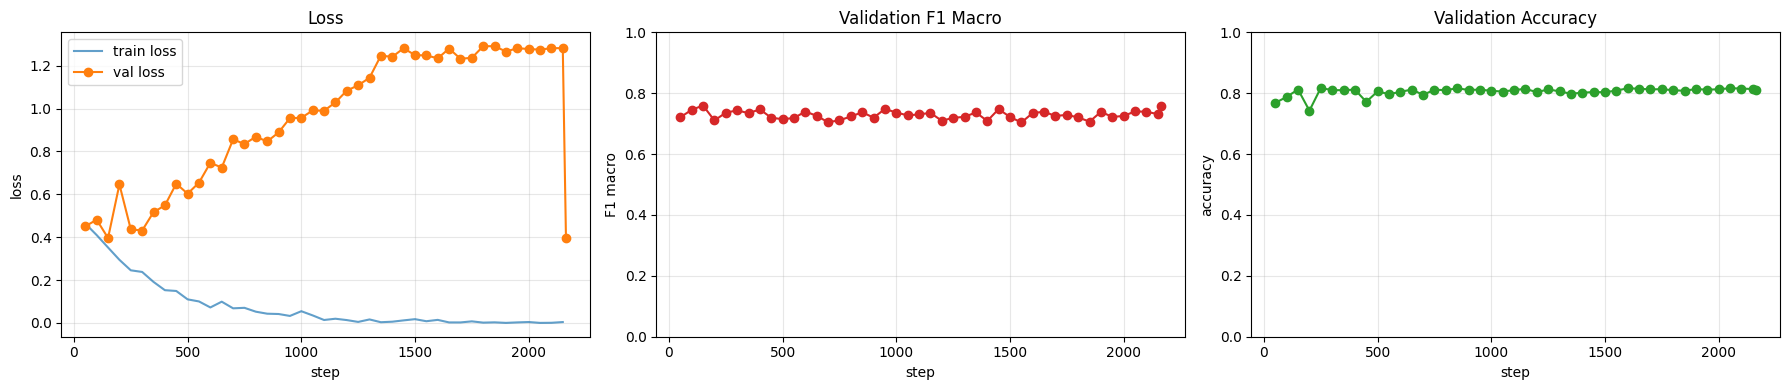

In [54]:
import matplotlib.pyplot as plt
import json
import pandas as pd

with open("/content/vit_oasis_best/log_history.json") as f:
    history = json.load(f)

logs = pd.DataFrame(history)
print(f"Loaded {len(logs)} log entries")

train_logs = logs[logs["loss"].notna()]
if "train_runtime" in logs.columns:
    train_logs = train_logs[train_logs["train_runtime"].isna()]

eval_logs = logs[logs["eval_loss"].notna()]
print(f"Train points: {len(train_logs)}, Eval points: {len(eval_logs)}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Loss
axes[0].plot(train_logs["step"], train_logs["loss"], label="train loss", alpha=0.7)
axes[0].plot(eval_logs["step"], eval_logs["eval_loss"], "o-", label="val loss", color="C1")
axes[0].set_xlabel("step"); axes[0].set_ylabel("loss")
axes[0].set_title("Loss"); axes[0].legend(); axes[0].grid(alpha=0.3)

# F1 macro
axes[1].plot(eval_logs["step"], eval_logs["eval_f1_macro"], "o-", color="C3")
axes[1].set_xlabel("step"); axes[1].set_ylabel("F1 macro")
axes[1].set_title("Validation F1 Macro"); axes[1].grid(alpha=0.3)
axes[1].set_ylim(0, 1)

# Accuracy
axes[2].plot(eval_logs["step"], eval_logs["eval_accuracy"], "o-", color="C2")
axes[2].set_xlabel("step"); axes[2].set_ylabel("accuracy")
axes[2].set_title("Validation Accuracy"); axes[2].grid(alpha=0.3)
axes[2].set_ylim(0, 1)

plt.tight_layout(); plt.show()

In [49]:
preds_out = trainer.predict(val_ds)
logits = preds_out.predictions             # (N, 2)
y_true = preds_out.label_ids               # (N,)
y_pred = logits.argmax(axis=1)             # (N,)
y_prob = torch.softmax(torch.tensor(logits), dim=-1).numpy()[:, 1]  # P(Demented)

print(f"Total val predictions: {len(y_true)}")
print(f"Predicted Demented: {y_pred.sum()} / {len(y_pred)}")

Total val predictions: 17202
Predicted Demented: 5441 / 17202


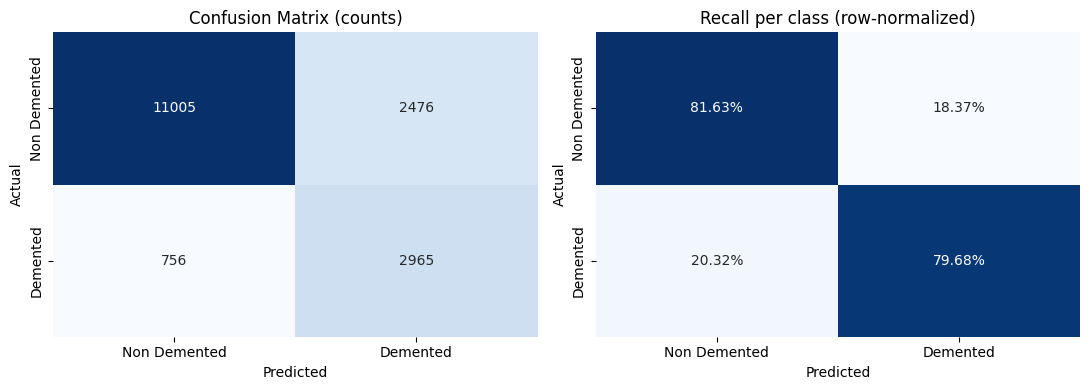

In [50]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)
labels = ["Non Demented", "Demented"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels, ax=axes[0], cbar=False)
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title("Confusion Matrix (counts)")

cm_norm = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Blues",
            xticklabels=labels, yticklabels=labels, ax=axes[1], cbar=False)
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
axes[1].set_title("Recall per class (row-normalized)")

plt.tight_layout();
plt.show()

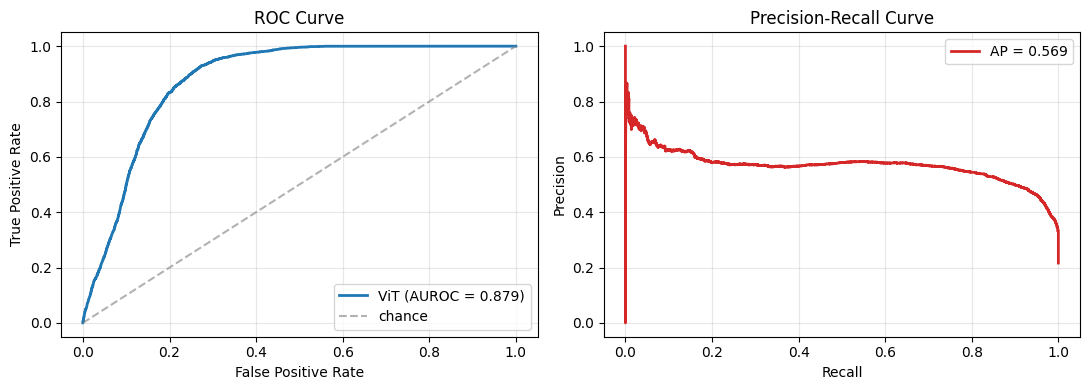


=== Classification Report ===
              precision    recall  f1-score   support

Non Demented     0.9357    0.8163    0.8720     13481
    Demented     0.5449    0.7968    0.6472      3721

    accuracy                         0.8121     17202
   macro avg     0.7403    0.8066    0.7596     17202
weighted avg     0.8512    0.8121    0.8233     17202



In [51]:
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score,
    classification_report,
)

fpr, tpr, _ = roc_curve(y_true, y_prob)
auroc = roc_auc_score(y_true, y_prob)

prec, rec, _ = precision_recall_curve(y_true, y_prob)
ap = average_precision_score(y_true, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(fpr, tpr, label=f"ViT (AUROC = {auroc:.3f})", linewidth=2)
axes[0].plot([0, 1], [0, 1], "--", color="gray", alpha=0.6, label="chance")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(rec, prec, label=f"AP = {ap:.3f}", linewidth=2, color="C3")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=labels, digits=4))

In [52]:
from sklearn.metrics import accuracy_score

val_with_preds = val_df.reset_index(drop=True).copy()
val_with_preds["pred"] = y_pred
val_with_preds["prob_demented"] = y_prob

patient_level = val_with_preds.groupby("subject").agg(
    true_label=("label", "first"),
    mean_prob=("prob_demented", "mean"),
    n_slices=("path", "count"),
).reset_index()
patient_level["pred"] = (patient_level["mean_prob"] >= 0.5).astype(int)

acc_slice   = (y_pred == y_true).mean()
acc_patient = accuracy_score(patient_level["true_label"], patient_level["pred"])
auroc_pat   = roc_auc_score(patient_level["true_label"], patient_level["mean_prob"])

print(f"Slice-level accuracy:   {acc_slice:.4f}  (N={len(y_true)})")
print(f"Patient-level accuracy: {acc_patient:.4f}  (N={len(patient_level)})")
print(f"Patient-level AUROC:    {auroc_pat:.4f}")

Slice-level accuracy:   0.8121  (N=17202)
Patient-level accuracy: 0.8286  (N=70)
Patient-level AUROC:    0.9097


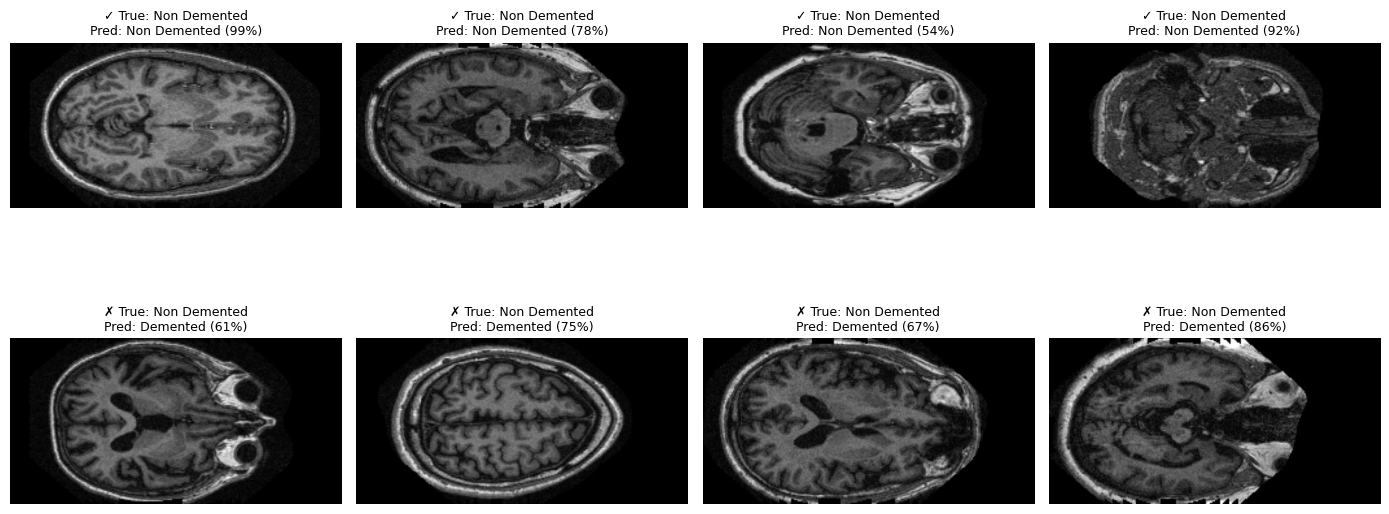

In [53]:
import numpy as np

correct_idx = np.where(y_pred == y_true)[0][:4]
incorrect_idx = np.where(y_pred != y_true)[0][:4]
idx_list = list(correct_idx) + list(incorrect_idx)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
label_names = {0: "Non Demented", 1: "Demented"}

for ax, idx in zip(axes.flat, idx_list):
    img = Image.open(val_df.iloc[idx]["path"]).convert("L")
    true = int(val_df.iloc[idx]["label"])
    pred = int(y_pred[idx])
    prob = y_prob[idx] if pred == 1 else (1 - y_prob[idx])
    mark = "✓" if pred == true else "✗"
    ax.imshow(img, cmap="gray")
    ax.set_title(f"{mark} True: {label_names[true]}\nPred: {label_names[pred]} ({prob:.0%})", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()